In [1]:
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

In [3]:
xgb.__version__

'3.1.3'

# XGBRegressor

In [4]:
data = {
    'size_sqft': [1000, 1500, 1200, 1800, 2000, 1100, 1600, 1300, 1900, 2100],
    'bedrooms': [2, 3, 2, 4, 4, 2, 3, 2, 4, 5],
    'age_years': [10, 5, 8, 2, 1, 12, 6, 9, 3, 1],
    'price': [200, 300, 250, 400, 450, 220, 350, 270, 420, 480]  # in $1000s
}
df = pd.DataFrame(data)
df.head()

,size_sqft,bedrooms,age_years,price
0,1000,2,10,200
1,1500,3,5,300
2,1200,2,8,250
3,1800,4,2,400
4,2000,4,1,450


In [5]:
X = df[['size_sqft', 'bedrooms', 'age_years']]  # Features
y = df['price']# target

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42  
)

In [7]:
X_train.shape,X_test.shape

((8, 3), (2, 3))

In [8]:
# XGBregressor
model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate = 0.1,
    min_child_weight = 1,
    # regularization parameters
    reg_alpha = 0,
    reg_gamma = 1,
    gamma =0,

    subsample = 0.8,
    colsample_bytree = 0.8,
    objective='reg:squarederror',  # Loss function to minimize
    random_state=42
)

In [9]:
model.get_params()

{'objective': 'reg:squarederror',
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': 0.8,
 'device': None,
 'early_stopping_rounds': None,
 'enable_categorical': False,
 'eval_metric': None,
 'feature_types': None,
 'feature_weights': None,
 'gamma': 0,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': 0.1,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': 3,
 'max_leaves': None,
 'min_child_weight': 1,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': 100,
 'n_jobs': None,
 'num_parallel_tree': None,
 'random_state': 42,
 'reg_alpha': 0,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': 0.8,
 'tree_method': None,
 'validate_parameters': None,
 'verbosity': None,
 'reg_gamma': 1}

In [10]:
model.fit(X_train,y_train)

/home/sureshsecond/venv/lib/python3.10/site-packages/xgboost/training.py:199: UserWarning: [09:55:45] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "reg_gamma" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [11]:
y_train_pred = model.predict(X_train)
y_test_pred= model.predict(X_test)
print(y_test.values)
print(y_test_pred)

[420 300]
[400.4074  315.34656]


In [12]:
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Model Performance:")
print(f"Training R² score: {train_r2:.3f}")
print(f"Test R² score: {test_r2:.3f}")
print(f"Training RMSE: {train_rmse:.2f}k")
print(f"Test RMSE: {test_rmse:.2f}k")

Model Performance:
Training R² score: 1.000
Test R² score: 0.914
Training RMSE: 0.84k
Test RMSE: 17.60k


     Feature  Importance
1   bedrooms    0.687275
0  size_sqft    0.289821
2  age_years    0.022904


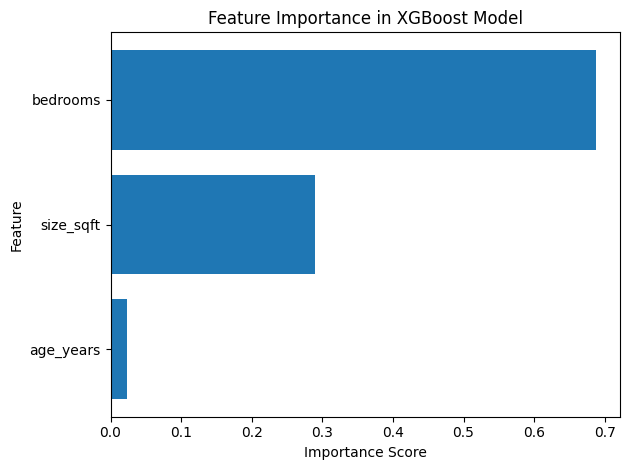

In [13]:
importances = model.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({
    "Feature":feature_names,
    "Importance":importances
}).sort_values('Importance',ascending=False)
print(importance_df)
# plot
plt.barh(importance_df['Feature'], importance_df['Importance'])
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.title('Feature Importance in XGBoost Model')
plt.gca().invert_yaxis()  # Highest importance at top
plt.tight_layout()
plt.show()

# XGBClassifier

In [15]:
from sklearn.datasets import make_classification

In [16]:
X, y = make_classification(
    n_samples=1000,  # 1000 emails
    n_features=20,   # 20 features (e.g., word counts, sender info, etc.)
    n_informative=15,  # 15 actually useful features
    n_redundant=5,   # 5 redundant features
    random_state=42
)

In [17]:
# y is binary: 0 = not spam, 1 = spam
print(f"number of 1's:{y.sum()}")
print(f"number of 0's:{len(y)-y.sum()}")

number of 1's:498
number of 0's:502


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
classifier = xgb.XGBClassifier(
    n_estimators = 100,
    objective='binary:logistic', # For binary classification # Uses log-loss (cross-entropy) # Outputs probabilities between 0 and 1
    # For imbalanced classes (e.g., 90% spam, 10% not spam)
    # scale_pos_weight=9,  # ratio of negative to positive class
                           # Gives more weight to minority class
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    random_state=42
)
classifier.fit(X_train,y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [20]:
y_pred = classifier.predict(X_test)
y_pred_proba = classifier.predict_proba(X_test)
print("First 5 predictions:")
print(f"Actual classes: {y_test[:5]}")
print(f"Predicted classes: {y_pred[:5]}")
print(f"Predicted probabilities (class 1 - spam):")
print(y_pred_proba[:5, 1]) 

First 5 predictions:
Actual classes: [0 1 1 0 1]
Predicted classes: [0 1 0 0 1]
Predicted probabilities (class 1 - spam):
[6.4942800e-04 9.9653339e-01 4.7123846e-01 1.9694399e-02 9.9906963e-01]


In [21]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print(f"This means {accuracy*100:.1f}% of predictions are correct")
print()

Accuracy: 0.920
This means 92.0% of predictions are correct



In [22]:
from sklearn.metrics import confusion_matrix, classification_report

In [23]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print("Explanation:")
print(f"True Negatives (correctly predicted not spam): {cm[0,0]}")
print(f"False Positives (wrongly predicted spam): {cm[0,1]}")
print(f"False Negatives (wrongly predicted not spam): {cm[1,0]}")
print(f"True Positives (correctly predicted spam): {cm[1,1]}")

Confusion Matrix:
[[98  8]
 [ 8 86]]
Explanation:
True Negatives (correctly predicted not spam): 98
False Positives (wrongly predicted spam): 8
False Negatives (wrongly predicted not spam): 8
True Positives (correctly predicted spam): 86


In [24]:
print("Classification Report:")
print(classification_report(y_test, y_pred, 
                          target_names=['Not Spam', 'Spam']))

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.92      0.92      0.92       106
        Spam       0.91      0.91      0.91        94

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



# XGBOOST NATIVE API (More Advanced)

     Convert data to DMatrix (XGBoost's internal data structure)
     THEORY: DMatrix is optimized for XGBoost, faster than numpy arrays
     It pre-processes and stores data efficientl

In [26]:
dtrain = xgb.DMatrix(data=X_train,label=y_train)
dtest = xgb.DMatrix(data=X_test,label=y_test)

In [30]:
# set parameters as dictionary
params = {
    'objective': 'reg:squarederror',  # Loss function
    'max_depth': 3,
    'eta': 0.1,  # learning_rate (XGBoost calls it eta)
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'lambda': 1,  # reg_lambda (L2 regularization)
    'alpha': 0,   # reg_alpha (L1 regularization)
    'eval_metric': 'rmse'  # Metric to monitor during training
}

In [33]:
evals = [(dtrain,'train'),(dtest,'test')] # Monitor both train and test

In [34]:
xgb_native = xgb.train(
    params,
    dtrain,
    num_boost_round=100, # Same as n_estimators
    evals= evals, # Datasets to monitor
    early_stopping_rounds=10, # Stop if no improvement for 10 rounds in test
    verbose_eval=10,# Print progress every 10 rounds
)

[0]	train-rmse:0.48186	test-rmse:0.48476
[10]	train-rmse:0.36787	test-rmse:0.39114
[20]	train-rmse:0.30922	test-rmse:0.35060
[30]	train-rmse:0.27393	test-rmse:0.32991
[40]	train-rmse:0.25054	test-rmse:0.32072
[50]	train-rmse:0.23313	test-rmse:0.31129
[60]	train-rmse:0.22186	test-rmse:0.30494
[70]	train-rmse:0.21105	test-rmse:0.29961
[80]	train-rmse:0.20250	test-rmse:0.29788
[90]	train-rmse:0.19321	test-rmse:0.29513
[99]	train-rmse:0.18564	test-rmse:0.29394


* early_stopping_rounds stops training when a monitored validation metric (defined in evals) fails to improve for a specified number of consecutive boosting rounds.
* If multiple metrics are provided in eval_metric, the last one listed is used to determine when to stop.

In [36]:
print(f"Best iteration: {xgb_native.best_iteration}")
print(f"Best test score: {xgb_native.best_score}")

Best iteration: 99
Best test score: 0.2939383925046497


# Handling Missing Values

In [39]:
print(*X_train.shape)

800 20


In [48]:
# Create data with missing values
X_with_missing = X_train.copy()

# Randomly set 10% of values to NaN (missing)
mask = np.random.rand(*X_with_missing.shape) < 0.1
X_with_missing[mask] = np.nan

In [51]:
print(f"Number of missing values: {np.isnan(X_with_missing).sum()}")

Number of missing values: 1636


In [57]:
# XGBoost handles missing values automatically
model_missing = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1
)

In [58]:
model_missing.fit(X_with_missing,y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [59]:
y_pred_missing = model_missing.predict(X_test)
score = r2_score(y_test, y_pred_missing)
print(f"R² score with missing values: {score:.3f}")

R² score with missing values: 0.639


# Cross validation

In [60]:
dtrain_full = xgb.DMatrix(X,label=y)
params = {
    'objective': 'reg:squarederror',
    'max_depth': 3,
    'eta': 0.1,
    'subsample': 0.8
}

In [62]:
# - Split data into 5 parts
# - Train on 4 parts, test on 1 part
# - Repeat 5 times, each part gets to be test set once
# - Average the results

In [61]:
cv_results = xgb.cv(
    params,
    dtrain_full,
    num_boost_round=100,
    nfold=5,
    metrics='rmse',
    early_stopping_rounds=10,
    seed=42,
    verbose_eval=10
)

[0]	train-rmse:0.47989+0.00061	test-rmse:0.48496+0.00158
[10]	train-rmse:0.35827+0.00298	test-rmse:0.39222+0.00824
[20]	train-rmse:0.29798+0.00162	test-rmse:0.35245+0.00744
[30]	train-rmse:0.26464+0.00295	test-rmse:0.33225+0.00740
[40]	train-rmse:0.24209+0.00395	test-rmse:0.32083+0.00775
[50]	train-rmse:0.22638+0.00514	test-rmse:0.31282+0.00713
[60]	train-rmse:0.21457+0.00549	test-rmse:0.30795+0.00718
[70]	train-rmse:0.20337+0.00556	test-rmse:0.30424+0.00802
[80]	train-rmse:0.19345+0.00530	test-rmse:0.30156+0.00848
[90]	train-rmse:0.18483+0.00515	test-rmse:0.29896+0.00838
[99]	train-rmse:0.17717+0.00532	test-rmse:0.29674+0.00832


In [63]:
print(cv_results)

    train-rmse-mean  train-rmse-std  test-rmse-mean  test-rmse-std
0          0.479887        0.000610        0.484959       0.001582
1          0.461654        0.001214        0.470457       0.003496
2          0.444824        0.001248        0.456642       0.004540
3          0.430408        0.001241        0.445299       0.005831
4          0.417894        0.001484        0.435783       0.007284
..              ...             ...             ...            ...
95         0.180258        0.005288        0.297954       0.008269
96         0.179246        0.005253        0.297639       0.008203
97         0.178586        0.005200        0.297384       0.008446
98         0.177833        0.005108        0.297042       0.008305
99         0.177171        0.005318        0.296739       0.008316

[100 rows x 4 columns]


In [64]:
type(cv_results)

pandas.core.frame.DataFrame

In [66]:
# get best iteration and score
best_iter = cv_results["test-rmse-mean"].idxmin()
best_score = cv_results.loc[best_iter,"test-rmse-mean"]
print(f"Best iteration: {best_iter}")
print(f"Best RMSE (average across 5 folds): {best_score:.3f}")

Best iteration: 99
Best RMSE (average across 5 folds): 0.297


# Hyperparameter Tuning

In [67]:
from sklearn.model_selection import GridSearchCV

In [78]:
data = {
    'size_sqft': [1000, 1500, 1200, 1800, 2000, 1100, 1600, 1300, 1900, 2100],
    'bedrooms': [2, 3, 2, 4, 4, 2, 3, 2, 4, 5],
    'age_years': [10, 5, 8, 2, 1, 12, 6, 9, 3, 1],
    'price': [200, 300, 250, 400, 450, 220, 350, 270, 420, 480]  # in $1000s
}
df = pd.DataFrame(data)
X = df[['size_sqft', 'bedrooms', 'age_years']]  # Features
y = df['price']# target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42  
)

In [79]:
X_train

,size_sqft,bedrooms,age_years
5,1100,2,12
0,1000,2,10
7,1300,2,9
2,1200,2,8
9,2100,5,1
4,2000,4,1
3,1800,4,2
6,1600,3,6


In [90]:
y

0    200
1    300
2    250
3    400
4    450
5    220
6    350
7    270
8    420
9    480
Name: price, dtype: int64

[CV] END learning_rate=0.01, max_depth=3, n_estimators=50, subsample=0.8; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, n_estimators=50, subsample=1.0; total time=   0.1s
[CV] END learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.3s
[CV] END learning_rate=0.01, max_depth=3, n_estimators=200, subsample=0.8; total time=   0.4s
[CV] END learning_rate=0.01, max_depth=3, n_estimators=200, subsample=1.0; total time=   0.4s
[CV] END learning_rate=0.01, max_depth=5, n_estimators=50, subsample=1.0; total time=   0.4s
[CV] END learning_rate=0.01, max_depth=5, n_estimators=100, subsample=0.8; total time=   0.7s
[CV] END learning_rate=0.01, max_depth=5, n_estimators=200, subsample=0.8; total time=   1.4s
[CV] END learning_rate=0.01, max_depth=5, n_estimators=200, subsample=1.0; total time=   1.4s
[CV] END learning_rate=0.01, max_depth=7, n_estimators=50, subsample=1.0; total time=   0.9s
[CV] END learning_rate=0.01, max_depth=7, n_estimators=100, subs

In [80]:
param_grid = {
    'max_depth': [3, 5, 7],           
    'learning_rate': [0.01, 0.1, 0.3],  
    'n_estimators': [50, 100, 200],   
    'subsample': [0.8, 1.0]           
}

In [81]:
base_model = xgb.XGBRegressor(random_state=42)

In [82]:
grid_search = GridSearchCV(
    base_model,
    param_grid,
    scoring="neg_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=2
)

In [83]:
grid_search.fit(X_train,y_train)

Fitting 3 folds for each of 54 candidates, totalling 162 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...], 'subsample': [0.8, 1.0]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [84]:
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {-grid_search.best_score_:.3f}")

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best cross-validation score: 3604.405


In [85]:
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)
best_test_score = r2_score(y_test, y_pred_best)

In [86]:
best_test_score

0.8510826826095581

In [97]:
best_model.fit(X,y)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


# Saving model

In [98]:
# method 1: pickle
import pickle

In [99]:
# save model
with open('xgboost_model.pkl','wb') as f:
    pickle.dump(best_model,f)

In [100]:
# load model
with open('xgboost_model.pkl','rb') as f:
    loaded_model = pickle.load(f)

In [101]:
loaded_model.predict(X_test)

array([420.1068, 299.8784], dtype=float32)

In [105]:
# Method 2: Using XGBoost's native format

# save
best_model.save_model("xgboost_model.json")

In [106]:
# load model
loaded_model_native = xgb.XGBRegressor()
loaded_model_native.load_model('xgboost_model.json')
print("Successfully loaded")

Successfully loaded
